# 13. Transport planning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/13_planning.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/13_planning.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-13.svg" alt="duckOSM notebook manual, chapter 13: Transport planning" width="100%">

| **You learn** | what GMNS is; the GMNS tables with `to_gmns`; the checks with `check_gmns`; the meso and micro networks; the network in path4gmns and a shortest path there; an AequilibraE project |
|---|---|
| **Time** | about 3 minutes |
| **Extras** | `duckosm[sim,planning,viz]` (the install cell installs them) |
| **Next** | [14. HD maps](14_hdmap.md): lane-level maps for driving simulators |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, os, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[sim,planning,viz] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version
# The network of chapter 1 (monaco.duckdb). The chapter opens it. When you run this chapter alone (in Colab), the file
# is not there, so this cell makes it one time.
if not os.path.exists("monaco.duckdb") or not duckosm.open("monaco.duckdb").has_mode("driving", "walking", "cycling"):
    duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], path="monaco.duckdb")

duckosm 0.8.0


## What GMNS is

Transport planners model the traffic of a city: where people travel, which routes they take, and what a new road or
a closed street changes. Their tools (path4gmns, DTALite, AequilibraE, Aimsun, Visum) need a network with more than
the roads: the **lanes** of each road and the **movements**, the turns that are allowed at each junction.

**GMNS** (General Modeling Network Specification, by the Zephyr Foundation) is a common format for such networks: a
set of tables, each one a CSV file or a database table.

| Table | One row for | Main columns |
|---|---|---|
| `link` | each road in one direction (a duckOSM edge) | `link_id`, `from_node_id`, `to_node_id`, `length`, `lanes`, `free_speed`, `capacity`, `allowed_uses` |
| `node` | each junction or end | `node_id`, `x_coord`, `y_coord` |
| `lane` | each lane of each link | `link_id`, `lane_num`, `allowed_uses`, `width` |
| `movement` | each allowed turn from one link to the next | `node_id`, `ib_link_id`, `ob_link_id`, `type` (thru, left, right, uturn ...) |
| `signal_controller` | each traffic signal | the node of the signal |

The module `duckosm.planning` makes these tables and gives them to the planning tools.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> The `link_id` of each GMNS link is the duckOSM `edge_id`, and the node ids are the OSM node ids. So the results of a planning tool join back to the network, to the map and to your data, as in chapter 12.

### Three levels of detail

GMNS has three levels. duckOSM makes all three in one DuckDB file.

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/gmns-levels.svg" alt="The levels of a GMNS network: the duckOSM network, the GMNS macro network, the meso network, the micro network, and the tools" width="100%">

The table compares the three levels: what one link is, the call that makes it, and its use.

| Level | One link for | The call | Use it for |
|---|---|---|---|
| macro | each road in one direction | `to_gmns` | static assignment, shortest paths |
| meso | each road, and each turn at a junction | `to_meso` | dynamic assignment with queues at the turns |
| micro | each cell of a lane (7 m), each lane change and each turn | `to_micro` | cell-based simulation of each lane |

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> The page [duckOSM for transport planning users](../compare/for-planning-users.md) compares each call with osm2gmns, path4gmns and AequilibraE.

## Open the network of chapter 1

Chapter 1 builds Monaco with three modes (driving, walking and cycling) and saves it as `monaco.duckdb`. This chapter opens that file with `duckosm.open`: it builds nothing. The planning tools use the driving network. The extra `sim` installs SUMO, because `to_gmns` takes the lanes
and the movements from SUMO's `netconvert`. The extra `planning` installs path4gmns.

In [2]:
net = duckosm.open("monaco.duckdb")    # the network of chapter 1: Monaco, three modes
net.driving                                                                # the card of the driving mode

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


The driving network of Monaco has 2840 edges and 1768 nodes, 96.2 km of roads.

## The GMNS tables: `to_gmns`

`net.driving.to_gmns(out_path)` (the same as `duckosm.planning.to_gmns(net.driving, out_path)`) writes the GMNS
tables in a new DuckDB file, in the schema `gmns_<mode>`. `net.to_gmns(out_path)` writes all the modes of the file,
one schema for each mode.

| Argument | Default | What it does |
|---|---|---|
| `mode`, `modes` | the mode of the view, else all modes | the modes to write |
| `to_csv` | none | a folder: also write each table as a CSV file |
| `lane_geometry` | `True` | a line for each lane, to draw the lanes |
| `combined` | `False` | also one network `gmns_all` for all the modes (needs two modes or more) |

The call gives a dict: the path, the rows of each table, and a report of the lanes that came from `netconvert`.

In [3]:
g = net.driving.to_gmns("out/gmns.duckdb")                   # the GMNS tables in a DuckDB file
g["modes"]                                                   # the rows of each table

GMNS out/gmns.duckdb: done in 25.7 s

{'driving': {'node': 1772,
  'link': 2858,
  'lane': 3318,
  'movement': 3755,
  'signal_controller': 1,
  'curb_seg': 0}}

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The progress line gives the time of the export: most of it is `netconvert`, which makes the lanes. The GMNS network has 2858 links and 1772 nodes: 18 links and 4 nodes more than the driving network. The 18 extra links are bus-only roads and contraflow bus lanes, which the driving network does not have (see `allowed_uses` below). The tables have 3318 lanes, 3755 movements and 1 signal controller.

In [4]:
g["sumo"]                                                    # the report of the lanes from netconvert

{'driving': {'movements': 3629,
  'rows': 3755,
  'connectors': 4123,
  'no_connection': 0,
  'lane_count_mismatch': 0,
  'no way out': 14,
  'no way in': 0,
  'against its arrow': 1,
  'arrows not matched': 6}}

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> Netconvert gave 4123 lane connectors for the 3755 movement rows. No movement is without a connection, and no link has a wrong number of lanes. 14 links have lanes with no way out. One movement goes against the turn arrow of its lane in OSM, and 6 turn arrows of OSM match no movement.

### Read the tables

The GMNS file is a DuckDB file, so you read it with SQL. This cell counts the rows of the four main tables, and
shows which uses the links allow.

In [5]:
import duckdb                                                # to read the GMNS tables

gmns = duckdb.connect("out/gmns.duckdb", read_only=True)     # the GMNS file
print(gmns.sql("""SELECT allowed_uses, count(*) AS links FROM gmns_driving.link GROUP BY 1 ORDER BY 2 DESC""").df())
gmns.sql("""SELECT 'link' AS table_name, count(*) AS rows FROM gmns_driving.link
            UNION ALL SELECT 'node', count(*) FROM gmns_driving.node
            UNION ALL SELECT 'lane', count(*) FROM gmns_driving.lane
            UNION ALL SELECT 'movement', count(*) FROM gmns_driving.movement""").df()    # the rows of the main tables

  allowed_uses  links
0         auto   2840
1     bus,bike     16
2          bus      2


,table_name,rows
0,link,2858
1,node,1772
2,lane,3318
3,movement,3755


2840 links allow `auto`: they are the driving edges. 2 links allow only `bus`, and 16
allow `bus,bike`: a bus-only edge allows bikes too when it is in the cycling network of the file. The four main tables have 2858 links, 1772 nodes, 3318 lanes and 3755 movements.

In [6]:
kinds = gmns.sql("""SELECT type, count(*) AS movements FROM gmns_driving.movement GROUP BY 1 ORDER BY 2 DESC""").df()   # the kinds of turn
gmns.close()                                                 # close the file: the next calls write to it
kinds

,type,movements
0,thru,2128
1,right,638
2,left,477
3,uturn,220
4,diverge,157
5,merge,135


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> Most movements go straight on (`thru`, 2128). There are 638 right turns, 477 left turns and 220 U-turns. `diverge` (157) and `merge` (135) are the movements where one road splits into two or two roads become one.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> Close your DuckDB connection to the GMNS file (`gmns.close()`) before the calls that follow. DuckDB refuses a second connection to a file with other settings in the same Python session, so `check_gmns`, `to_meso` and `to_micro` fail while it is open.

### The CSV files

Most planning tools read GMNS as CSV files. `to_csv=` writes one CSV file for each table, next to the DuckDB file.

In [7]:
import os
net.driving.to_gmns("out/gmns_csv.duckdb", to_csv="out/gmns_csv")    # the DuckDB file and the CSV files
sorted(os.listdir("out/gmns_csv"))                                 # the CSV files

GMNS out/gmns_csv.duckdb: done in 25.3 s

['config.csv',
 'curb_seg.csv',
 'geometry.csv',
 'lane.csv',
 'link.csv',
 'location.csv',
 'movement.csv',
 'node.csv',
 'signal_controller.csv',
 'use_definition.csv',
 'use_group.csv',
 'zone.csv']

The folder has 12 CSV files, one for each GMNS table, for example `link.csv`,
`node.csv`, `lane.csv` and `movement.csv`.

## Check the tables: `check_gmns`

`duckosm.planning.check_gmns(path)` runs a set of checks on each `gmns_<mode>` schema of a GMNS file: each link
starts and ends at its nodes, each link has lanes, each movement turns where its links meet, and more. It gives one
tuple for each check: the schema, the check, the bad rows and all the rows. `modes=` limits the checks to some
modes.

In [8]:
checks = duckosm.planning.check_gmns("out/gmns.duckdb")      # (schema, check, bad rows, rows) for each check
print(len(checks), "checks;", [c for c in checks if c[2] > 0], "with bad rows")
checks[:5]                                                   # the first checks

17 checks; [] with bad rows


[('gmns_driving', 'link starts at its from_node', 0, 2858),
 ('gmns_driving', 'link ends at its to_node', 0, 2858),
 ('gmns_driving', 'link from_node / to_node exist', 0, 2858),
 ('gmns_driving', 'link is not a loop', 0, 2858),
 ('gmns_driving', "link.length is its geometry's length", 0, 2858)]

`check_gmns` runs 17 checks, and no check has a bad row. Each tuple tells the check
and its numbers: for example, all 2858 links start at their `from_node`.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> Run `check_gmns` after each change to the GMNS tables, and before you give them to a planning tool.

## The meso network: `to_meso`

`duckosm.planning.to_meso(gmns_db)` adds the schema `meso_<mode>` (tables `meso_node` and `meso_link`) to the GMNS
file. It has two kinds of link: a **normal** link for each macro link, and a **movement** link for each allowed turn.
The ids stay the same in each build: `M<edge_id>` for a normal link, `X<from>-<to>` for a movement. `macro_link_id`
is the `edge_id` of the macro link. `trim_m` (default 6 m) cuts each link at its ends, to make room for the turns.

In [9]:
duckosm.planning.to_meso("out/gmns.duckdb")                  # meso_driving.meso_node and meso_link

{'driving': {'meso_node': 5716,
  'normal': 2858,
  'movement': 3755,
  'meso_link': 6613}}

The meso network has 6613 links: 2858 normal links (one for each macro link) and 3755
movement links (one for each movement). It has 5716 nodes, two for each normal link (2 × 2858).

## The micro network: `to_micro`

`duckosm.planning.to_micro(gmns_db)` adds the schema `micro_<mode>`. Each lane is cut into **cells** of
`cell_length_m` (default 7 m, about one car). The other links are the **lane changes** between two lanes side by side,
and the **movements** from the end of a lane to the start of a lane of the next link. `macro_link_id` and `lane_no`
tell the macro link and the lane of each cell.

In [10]:
duckosm.planning.to_micro("out/gmns.duckdb")                 # micro_driving.micro_node and micro_link

{'driving': {'micro_node': 18401,
  'cell': 15083,
  'lane_change': 3163,
  'movement': 4123,
  'micro_link': 22369}}

The micro network has 22369 links: 15083 cells, 3163 lane changes and 4123 movements
(one for each lane connector of netconvert). It has 18401 nodes.

## path4gmns: `to_path4gmns`

path4gmns is a Python tool for shortest paths, traffic assignment and DTALite (dynamic traffic assignment).
`duckosm.planning.to_path4gmns(gmns_db)` writes `node.csv` and `link.csv` of one mode (default `driving`) and loads
them with path4gmns, with the lengths in metres and the speeds in km/h. `out_dir` is the folder of the two files
(default: a folder `path4gmns` next to the GMNS file). The result is the path4gmns network.

In [11]:
pnet = duckosm.planning.to_path4gmns("out/gmns.duckdb")    # the network in path4gmns

path4gmns, version 0.10.0

read node.csv
the number of nodes is 1,772
the number of zones is 1

read link.csv
the number of links is 2,858



Path4gmns reads 1772 nodes and 2858 links, the numbers of the GMNS tables. All the
nodes are in one zone, zone 1.

### The same shortest path in two tools

The node ids of path4gmns are the OSM node ids, and its link ids are the edge ids. So a route of duckOSM (chapter 7)
can go to path4gmns. This cell finds the shortest route by length in duckOSM, gives its first and last node to
path4gmns, and compares the two routes.

In [12]:
route = net.driving.route((7.4155, 43.7285), (7.4335, 43.7468), weight="length")    # the shortest route in duckOSM
ends = net.driving.edges(where=f"edge_id IN ({route['edges'][0]}, {route['edges'][-1]})").set_index("edge_id")
start, end = int(ends.source[route["edges"][0]]), int(ends.target[route["edges"][-1]])    # its first and last node
found = pnet.find_shortest_path(start, end, mode="auto", seq_type="link", cost_type="distance")    # the same in path4gmns
links = [int(x) for x in found.split("link path: ")[1].split(";")]                            # its links (edge ids)
round(route["length_m"]), found.split(" | ")[0], links == route["edges"]    # the two lengths, and the same edges?

(2937, 'path distance: 2917.8829 meters', True)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The two tools find the same edges (`True`). The duckOSM length, 2937 m, includes about 22 m from the two points to the road. The edges alone are 2916 m long, and path4gmns gives 2918 m for the same links, from the lengths of the GMNS links.

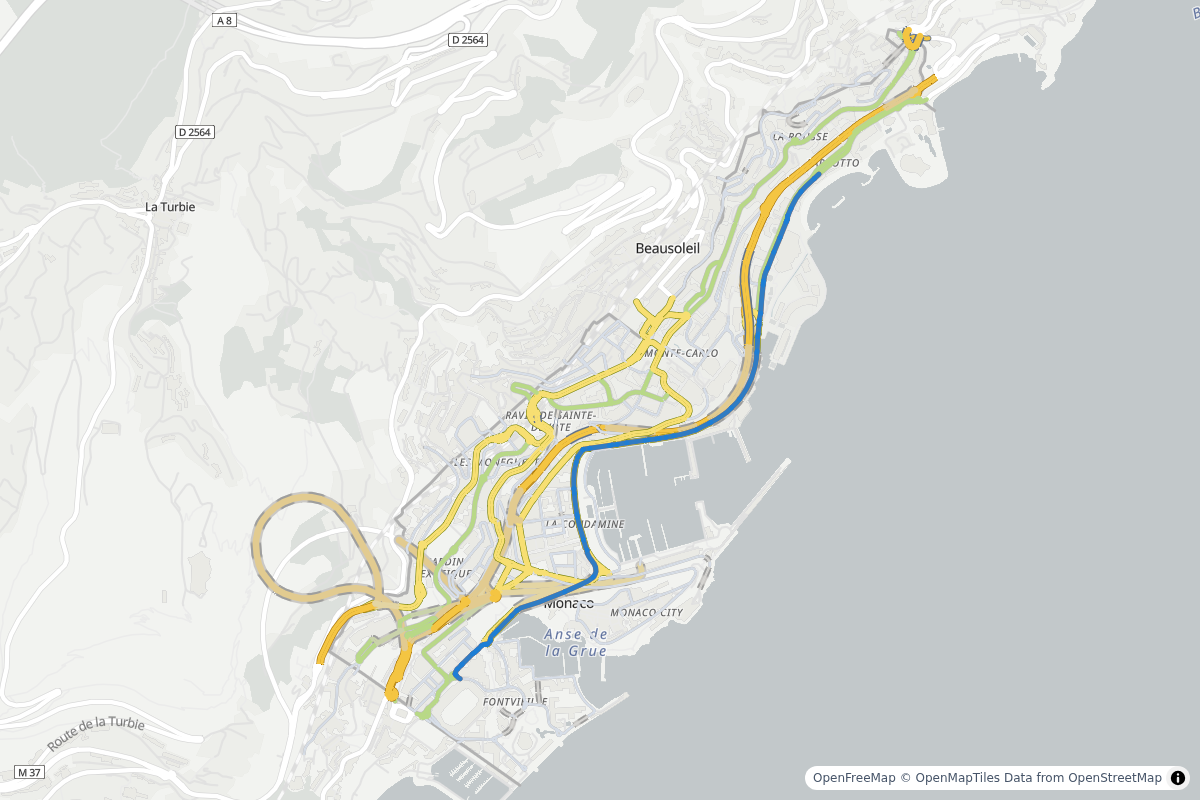

In [13]:
net.driving.map(routes={"duckOSM": route, "path4gmns": {"edges": links}})    # the two routes on the map

The two routes are on the same edges, so the map shows one line from the south-west
to the north-east of Monaco.

## AequilibraE: `to_aequilibrae`

AequilibraE is a Python tool for transport models: skims, traffic assignment and the transit network.
`duckosm.planning.to_aequilibrae(net.driving, project_dir)` makes a new AequilibraE project in a folder that must not
exist. Each edge becomes one link, with:

| Field | Value |
|---|---|
| `direction` | 1: from the `source` node to the `target` node of the edge |
| `speed_ab` | `maxspeed_kmh` |
| `capacity_ab` | the lanes × the capacity of one lane of the road class, as in GMNS |
| `travel_time_ab` | `cost_s` in minutes |
| `modes` | `c` (car), `w` (walk) or `b` (bicycle), from the mode |
| `link_type` | the OSM `highway` |
| `edge_id` | the duckOSM `edge_id` |

AequilibraE makes the nodes from the ends of the links. The call gives `{path, links, nodes}`.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> AequilibraE is not in an extra of duckOSM. Install it with `pip install aequilibrae` (Python 3.11 or later), and install SpatiaLite (`apt install libsqlite3-mod-spatialite`). The cell below runs the call only when AequilibraE is installed.

In [14]:
import importlib.util
if importlib.util.find_spec("aequilibrae"):                               # AequilibraE is installed
    print(duckosm.planning.to_aequilibrae(net.driving, "out/aequilibrae"))   # the project: path, links, nodes
else:
    print("AequilibraE is not installed: pip install aequilibrae, and SpatiaLite")

AequilibraE is not installed: pip install aequilibrae, and SpatiaLite


AequilibraE is not installed here, so the cell prints the line to install it. With
AequilibraE, the call prints the folder of the project, its links (one for each edge) and its nodes.

## Try it yourself

**1.** Write the GMNS tables of driving and walking in one file, with the combined network `gmns_all`. Build a network with the two modes first.

<details><summary>Show the answer</summary>

```python
both = duckosm.open("monaco.duckdb")
r = both.to_gmns("out/gmns_dw.duckdb", combined=True)       # gmns_driving, gmns_walking and gmns_all
r["modes"].keys(), r["combined"]
```
</details>

**2.** Make the micro network with cells of 14 m, and compare the number of cells with the 7 m cells.

<details><summary>Show the answer</summary>

```python
duckosm.planning.to_micro("out/gmns.duckdb", cell_length_m=14.0)["driving"]["cell"]
```
</details>

**3.** Find the five links of the GMNS table with the highest capacity, with their names.

<details><summary>Show the answer</summary>

```python
gmns = duckdb.connect("out/gmns.duckdb", read_only=True)
gmns.sql("SELECT link_id, name, lanes, capacity FROM gmns_driving.link ORDER BY capacity DESC LIMIT 5").df()
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| GMNS | General Modeling Network Specification: a common table format for transport networks |
| link | a road in one direction: in duckOSM, one edge |
| lane | one lane of a link, with its uses and its width |
| movement | an allowed turn at a junction, from one link to the next |
| macro, meso, micro | the three levels of detail of a network: roads, roads and turns, lane cells |
| cell | a short part of a lane in the micro network (7 m by default) |
| capacity | the number of vehicles a link can carry in one hour |
| traffic assignment | the step of a model that puts the trips on routes of the network |
| path4gmns | a Python tool for shortest paths and traffic assignment on GMNS networks |
| AequilibraE | a Python tool for transport models |

## Summary

| Call | Does |
|---|---|
| `net.driving.to_gmns(out_path, ...)`, `duckosm.planning.to_gmns(...)` | the GMNS tables (link, node, lane, movement) in a DuckDB file, and with `to_csv=` also the CSV files |
| `duckosm.planning.check_gmns(path)` | the checks of the GMNS tables |
| `duckosm.planning.to_meso(gmns_db)` | the meso network: a link for each road and each turn |
| `duckosm.planning.to_micro(gmns_db)` | the micro network: lane cells, lane changes and turns |
| `duckosm.planning.to_path4gmns(gmns_db)` | the network loaded in path4gmns |
| `duckosm.planning.to_aequilibrae(view, project_dir)` | a new AequilibraE project with the links |

The reference: [duckosm.planning](../reference/sdk/planning.md). **Next:** [14. HD maps](14_hdmap.md), lane-level maps for driving simulators.